MUHAMMAD YUSUF
2411512010
PEMOGRAMAN PARALEL B

1.1 operasi pada arr + arr pada NumPy array merupakan kategori SIMD,      alasannya adalah pada numpy instruksi dieksekusi secara bersamaan. Jadi pada contoh kasus array ditambah array, komputer hanya menerima satu perintah penambahan yang akan dieksekusi ke seluruh elemen yang ada pada array.

1.2 Program Python biasa (tanpa threading/multiprocessing) membaca file baris demi baris termasuk kedalam kategori SISD, alasannya adalah prosesor hanya menjalankan satu instruksi dalam satu waktu (satu baris diselesaikan, lalu lanjut baris berikutnya).

1.3 Cluster komputer yang masing-masing node nya menajalankan simulasi cuaca untuk wilayah berbeda secara independen termasuk kedalam kategori MIMD, sebab pada soal disebutkan bahwasannya simulasi dilakukan secara independen pada masing-masing node komputer. Terdapat banyak instruksi pada banyak data. 

2.1  rumus dari hukum amdahl adalah = S(N) = 1/(1-P)+(P/N)
dimana diketahui pada soal nilai P = 0.85

In [4]:
def amdahl_speedup(P, N):
    return 1 / ((1 - P) + (P / N))

P = 0.85
N = [2, 4, 8, 16, 32, 64]

for N in N:
    speedup = amdahl_speedup(P, N)
    print(f"Speedup untuk N : {speedup:.4f}")

Speedup untuk N : 1.7391
Speedup untuk N : 2.7586
Speedup untuk N : 3.9024
Speedup untuk N : 4.9231
Speedup untuk N : 5.6637
Speedup untuk N : 6.1244


Penjelasan kode :
pada dua baris awal dideklarasikan fungsi bernama amdahl_speedup yang akan menerima dua variabel, yaitu P dan N. Lalu dimasukkan rumus hukum amdahl yang telah dipelajari.
selanjutnya dideklarasikan nilai dari P dan N yang didapat dari soal, P bernilai 0.85, dan N bernilai 2,4,8,16,31,64
Lalu dibuat fungsi loop agar setiap anggota dari N dieksekusi seluruhnya dan ditampilkan ke terminal.
Hasil :
Speedup untuk N = 2 adalah 1.7391,
Speedup untuk N = 4 adalah 2.7586,
Speedup untuk N = 8 adalah 3.9024,
Speedup untuk N = 16 adalah 4.9231,
Speedup untuk N = 32 adalah 5.6637,
Speedup untuk N = 64 adalah 6.1244,


2.2 Plot dari speedup

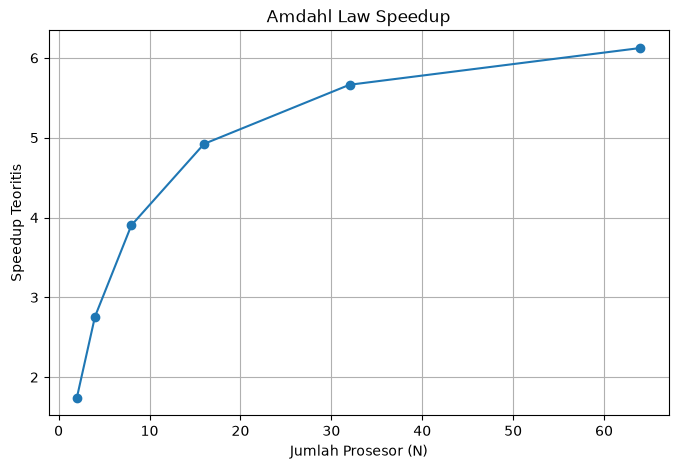

In [14]:
import matplotlib.pyplot as plt

def amdahl_speedup(P, N):
    return 1 / ((1 - P) + (P / N))

N = [2, 4, 8, 16, 32, 64]
P = 0.85
speedups = []                
for n in N:                  
    hasil = amdahl_speedup(P, n) 
    speedups.append(hasil)

plt.figure(figsize=(8, 5))
plt.plot(N, speedups, marker='o')
plt.title(f"Amdahl Law Speedup")
plt.xlabel('Jumlah Prosesor (N)')
plt.ylabel('Speedup Teoritis')
plt.grid(True)
plt.show()

Penjelasan kode :
Pada 3 baris pertama dilakukan import library matplotlib.pyplot yang berguna untuk menggambar grafik dan disingkat menjadi plt. Lalu fungsi untuk menghitung hukum amdahl.

NIlai P dan N dideklarasikan. Lalu dibuat perulangan bernama speedups[] yang akan menggunakan nilai P tetap yaitu 0.85, dan nilai n yang berubah setiap perulangan. Digunakan juga .append agar hasil yang baru ditambahkan ke urutan belakang dari list

Lalu dibuatkan format dari grafik 
plt.figure unruk mengatur ukuran kanvas (8,5),
plt.plot (N sebagai sumbu x, speedups sebagai sumbu y, dan marker='o' untuk menggambarkan titik pada pertemuan koordinat),
plt.title sebagai judul dari grafik,
plt.xlabel untuk memberi keterangan di sumbu x,
plt.ylabel untuk memberi keterangan di sumbu y,
plt.grid ditambahkan untuk memudahkan pembacaan grafik,
plt.show digunakan agar grafik dapat muncul,

2.3 Menurut perhitungan hukum amdahl, speedup maksimum dapat ditemukan pada limit N mendekati tak hingga, dengan rumus S(N) = 1/(1-P). Setelah dilakukan perhitungan, nilainya adalah 1/0.15 = 6.667. pada saat penambahan prosessor dari 16 menjadi 32, nilai speedup sudah mencapai 5.664, yang dimana nilai ini sudah mencapai 84,96% dari nilai maksimal. Menambah prosessor dua kali lipat dari angka ini sudah tidak menguntungkan lagi jika membandingkan performa dengan biaya yang dikeluarkan.

3.

In [28]:
import time
import timeit
import pandas as pd

def hitung_prima(n):
    
    primes = []
    for num in range(2, n):
        is_prime = True
        for i in range(2, int(num ** 0.5) + 1):
            if num % i == 0:
                is_prime = False
                break
        if is_prime:
            primes.append(num)
    return primes

input = [13, 19, 300, 260306]
hasil = []


for n in input:
    
    mulai = time.perf_counter()
    hitung_prima(n)
    selesai = time.perf_counter()
    time_perf = selesai - mulai
    
    stmt = f"hitung_prima({n})"
    setup = "from __main__ import hitung_prima"
    time_timeit = timeit.timeit(stmt, setup=setup, number=5) / 5
    
    
    hasil.append({
        "N (Input Size)": n,
        "perf_counter (detik)": time_perf,
        "timeit (detik)": time_timeit
    })

df = pd.DataFrame(hasil)
print(df)

   N (Input Size)  perf_counter (detik)  timeit (detik)
0              13              0.000012        0.000003
1              19              0.000006        0.000005
2             300              0.000106        0.000090
3          260306              0.387200        0.378949


Penjelasan kode :
3 baris awal untuk memanggil library timeit agar time_timeit bisa digunakan, time time.perf bisa digunakan, dan pandas yang berguna untuk membuat tabel

lalu fungsi hitung_prima yang sudah dibuat di materi dimasukkan

dideklarasikan juga variabel input dan hasil

lalu dibuatkan fungsi perulangan untuk menguji setiap input dengan kedua metode.

pada metode time.perf_counter :
pada bagian 'mulai' perintah time.perf_counter dimulai dan mulai menghitung waktu
lalu fungsi hitung_prima dijalankan
pada bagial 'selesai' time.perf_counter dibuat lagi untuk menghentikan perhitungan waktu
lalu pada akhir waktu selesai dikurangi dengan waktu start untuk mengetahui waktu eksekusi sebenarnya

pada metode timeit :
stmt digunakan untuk mengambil data yang akan digunakan pada perulangan pertama
setup memberitahu timeit dimana letak dari fungsi hitung_prima
time_timeit akan menjalankan kode stmt sebanyak 5 kali dan membagi 5 untuk mendapatkan hasil rata ratanya

lalu hasil disimpan dalam hasil dan dibuatkan tabelnya menggunakan perintah df


4. Hukum amdahl digunakan ketika masalah yang dihadapi tidak bisa berubah, yang dimana tujuannya adalah menyelesaikan tugas yang pasti tersebut secepat mungkin. Contoh nyatanya adalah saat render vidio, pada langkah encoding proses bersifat serial dimana penambahan core tidak akan mempercepat proses tersebut sehingga terjadi bottleneck.

Hukum gustafson relevan digunakan ketika skala dari permasalahan dapat diperbesar. Contohnya adalah ketika training model AI untuk computer vision. Jika saya memiliki GPU atau CPU baru yang lebih canggih dari laptop yang saya gunakan sekarang, misalnya dalam waktu 3 jam saya bisa memproses 1000 dataset, dengan GPU atau CPU baru saya bisa training 5000 dataset dengan waktu yang sama. Saya tidak ingin proses selesai lebih cepat, namun ingin menyelesaikan lebih banyak proses di waktu yang sama.